# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

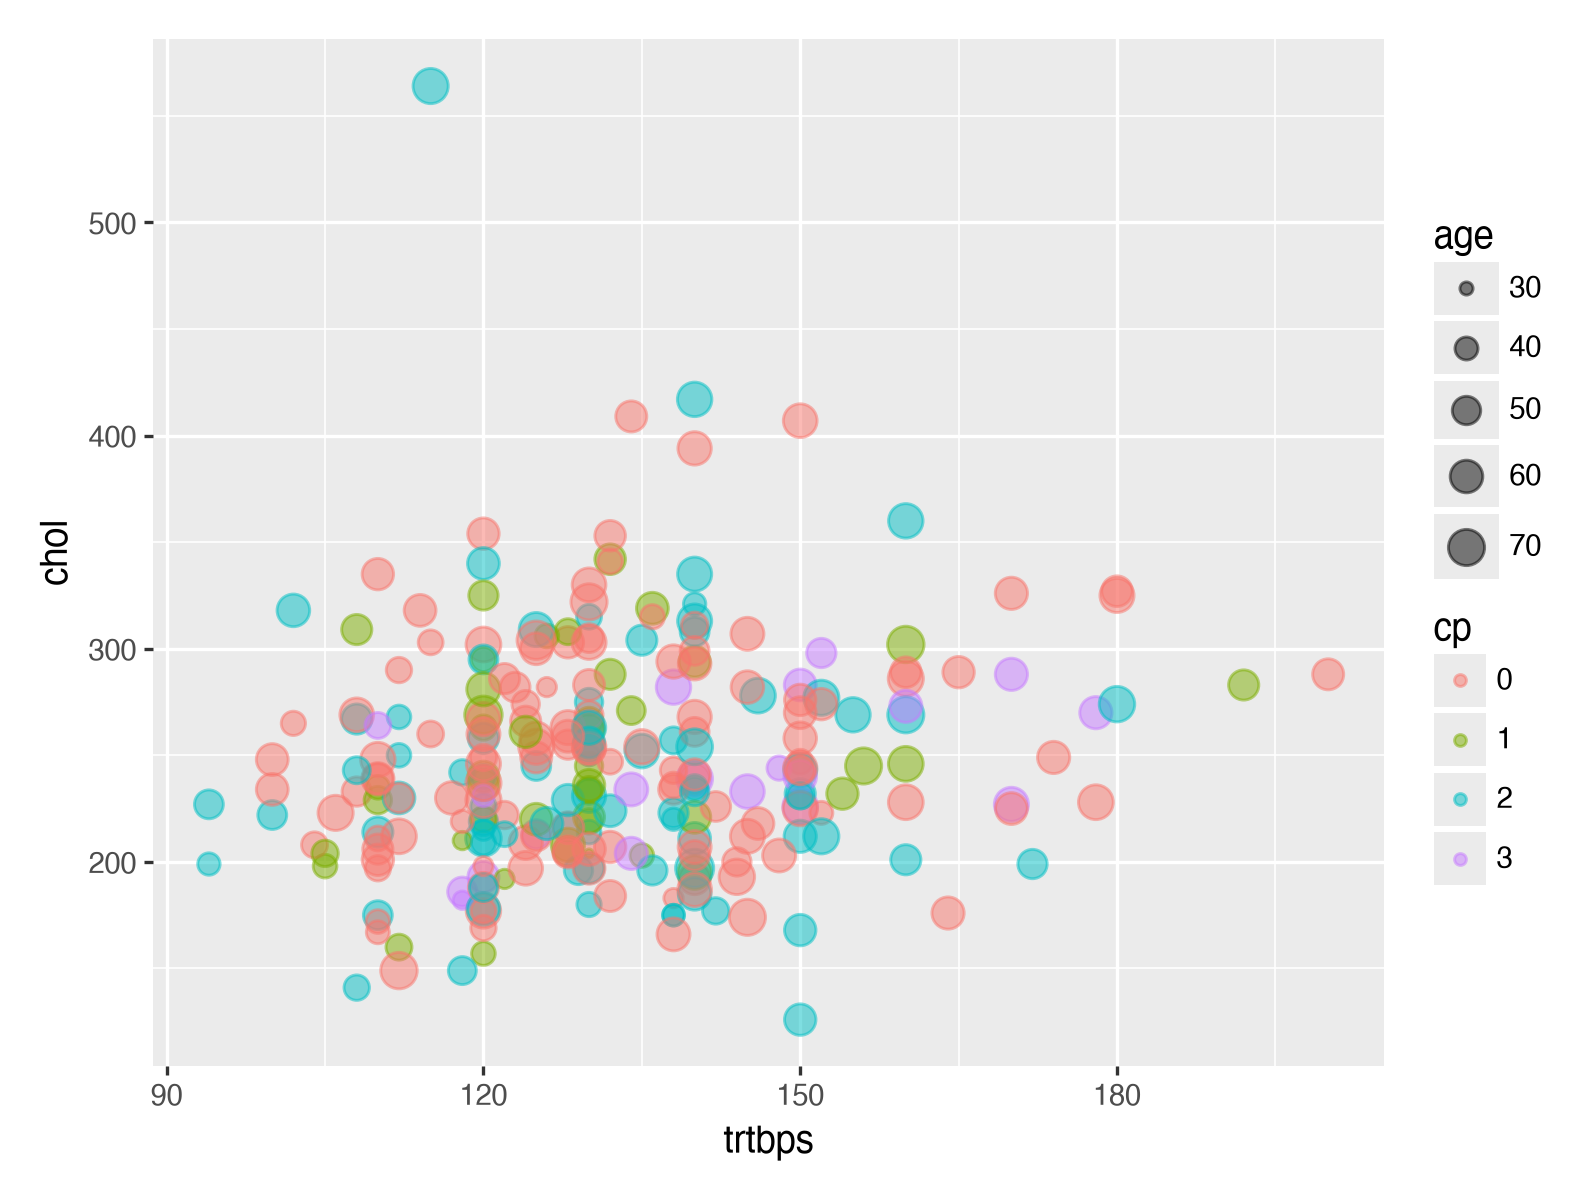

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


,0,1,2,3
133,0.4,0.2,0.1,0.3
157,0.5,0.1,0.3,0.1
130,0.2,0.2,0.6,0.0
78,0.6,0.0,0.3,0.1
247,0.4,0.2,0.3,0.1
...,...,...,...,...
56,0.4,0.1,0.4,0.1
21,0.4,0.2,0.3,0.1
40,0.4,0.2,0.3,0.1
94,0.5,0.1,0.4,0.0


test accuracy: 0.463768115942029
              precision    recall  f1-score   support

           0       0.49      0.78      0.60        32
           1       0.00      0.00      0.00        11
           2       0.50      0.33      0.40        21
           3       0.00      0.00      0.00         5

    accuracy                           0.46        69
   macro avg       0.25      0.28      0.25        69
weighted avg       0.38      0.46      0.40        69



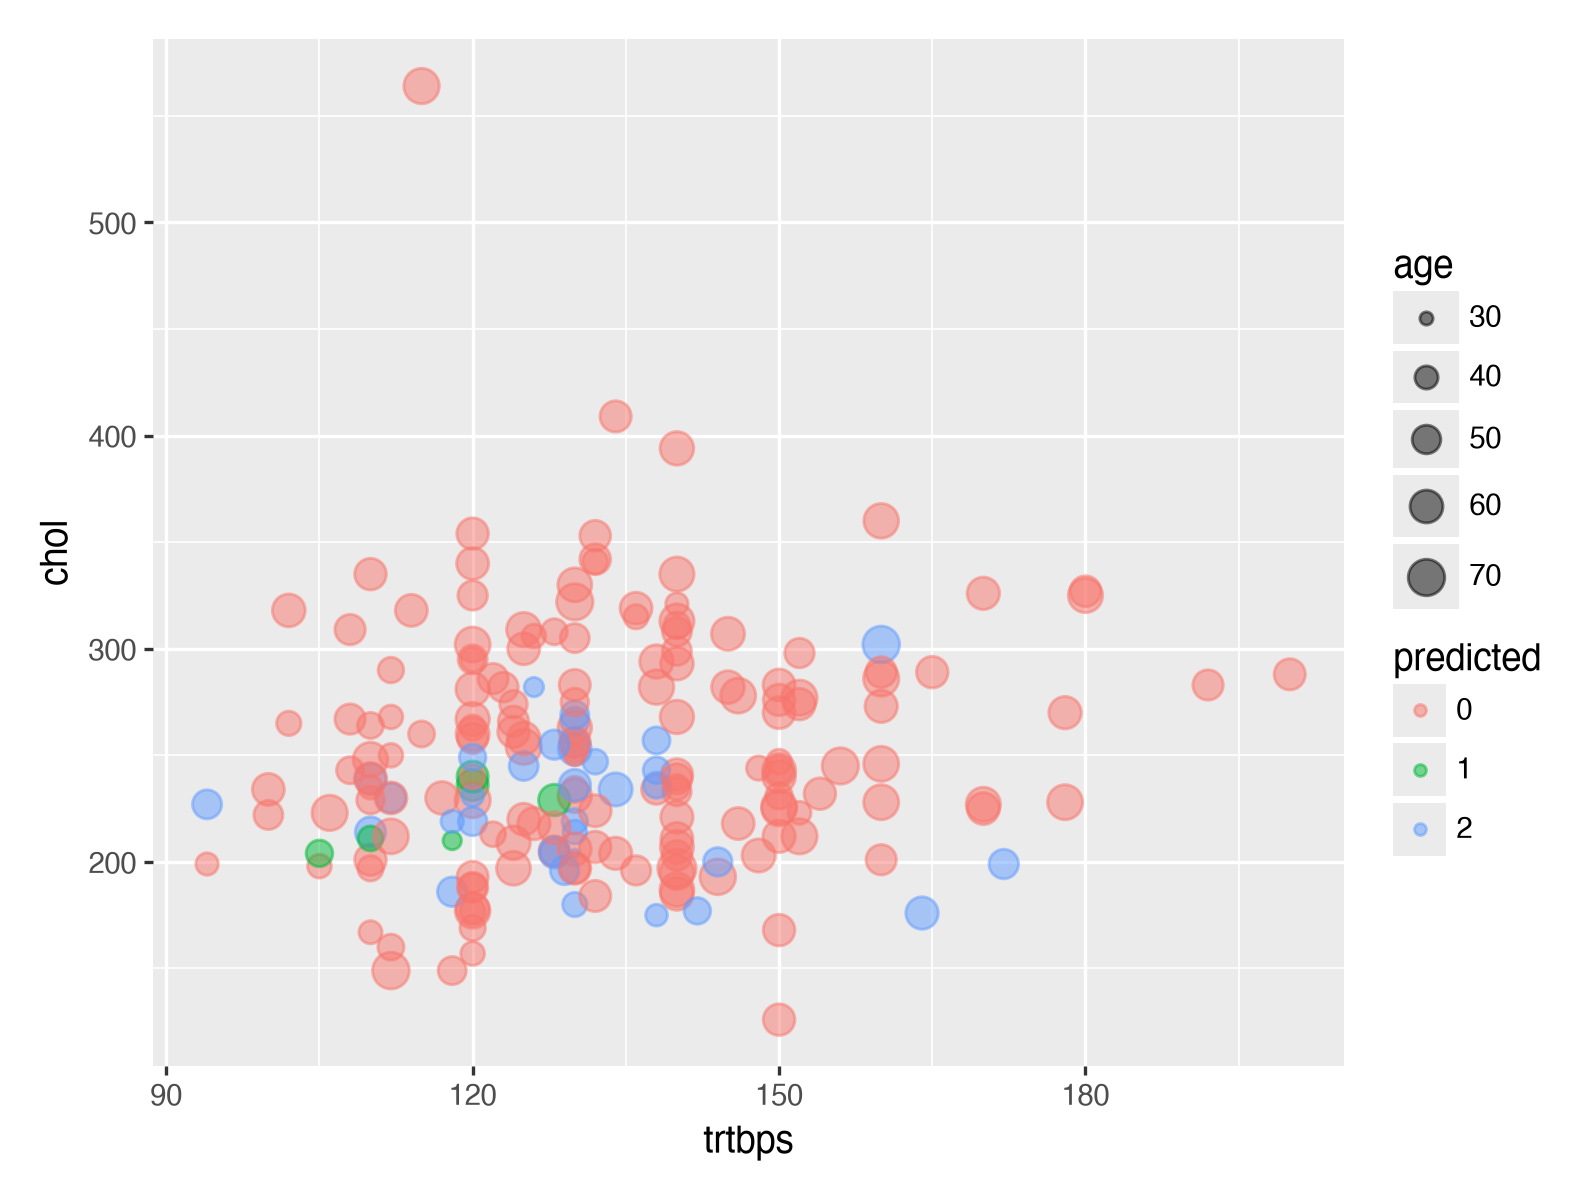

In [5]:
X = ha[["trtbps", "chol", "age"]]
y = ha["cp"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

knn.fit(X_train, y_train)

display(pd.DataFrame(knn.predict_proba(X_train), columns=knn.classes_, index=X_train.index))

knn_pred = knn.predict(X_test)
print("test accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred, zero_division=0))

knn_plot = X_train.assign(predicted=knn.predict(X_train))
(ggplot(knn_plot, aes(x="trtbps", y="chol", size="age", color="predicted"))
+ geom_point(alpha=0.5))

Some classes are much less common than others, especially class 3. The predictors also overlap across classes. The model may rarely or never predict a less common class, giving it a recall and F1 of 0. Precision is undefined if there are no predictions for that class; zero_division=0 reports it as 0. The macro average gives each class equal weight.

## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

,not class 3,class 3
133,0.819992,0.180008
157,0.935894,0.064106
130,0.927973,0.072027
78,0.924506,0.075494
247,0.896819,0.103181
...,...,...
56,0.908802,0.091198
21,0.883856,0.116144
40,0.921442,0.078558
94,0.852195,0.147805


test precision: 0.0
test recall: 0.0
test f1: 0.0


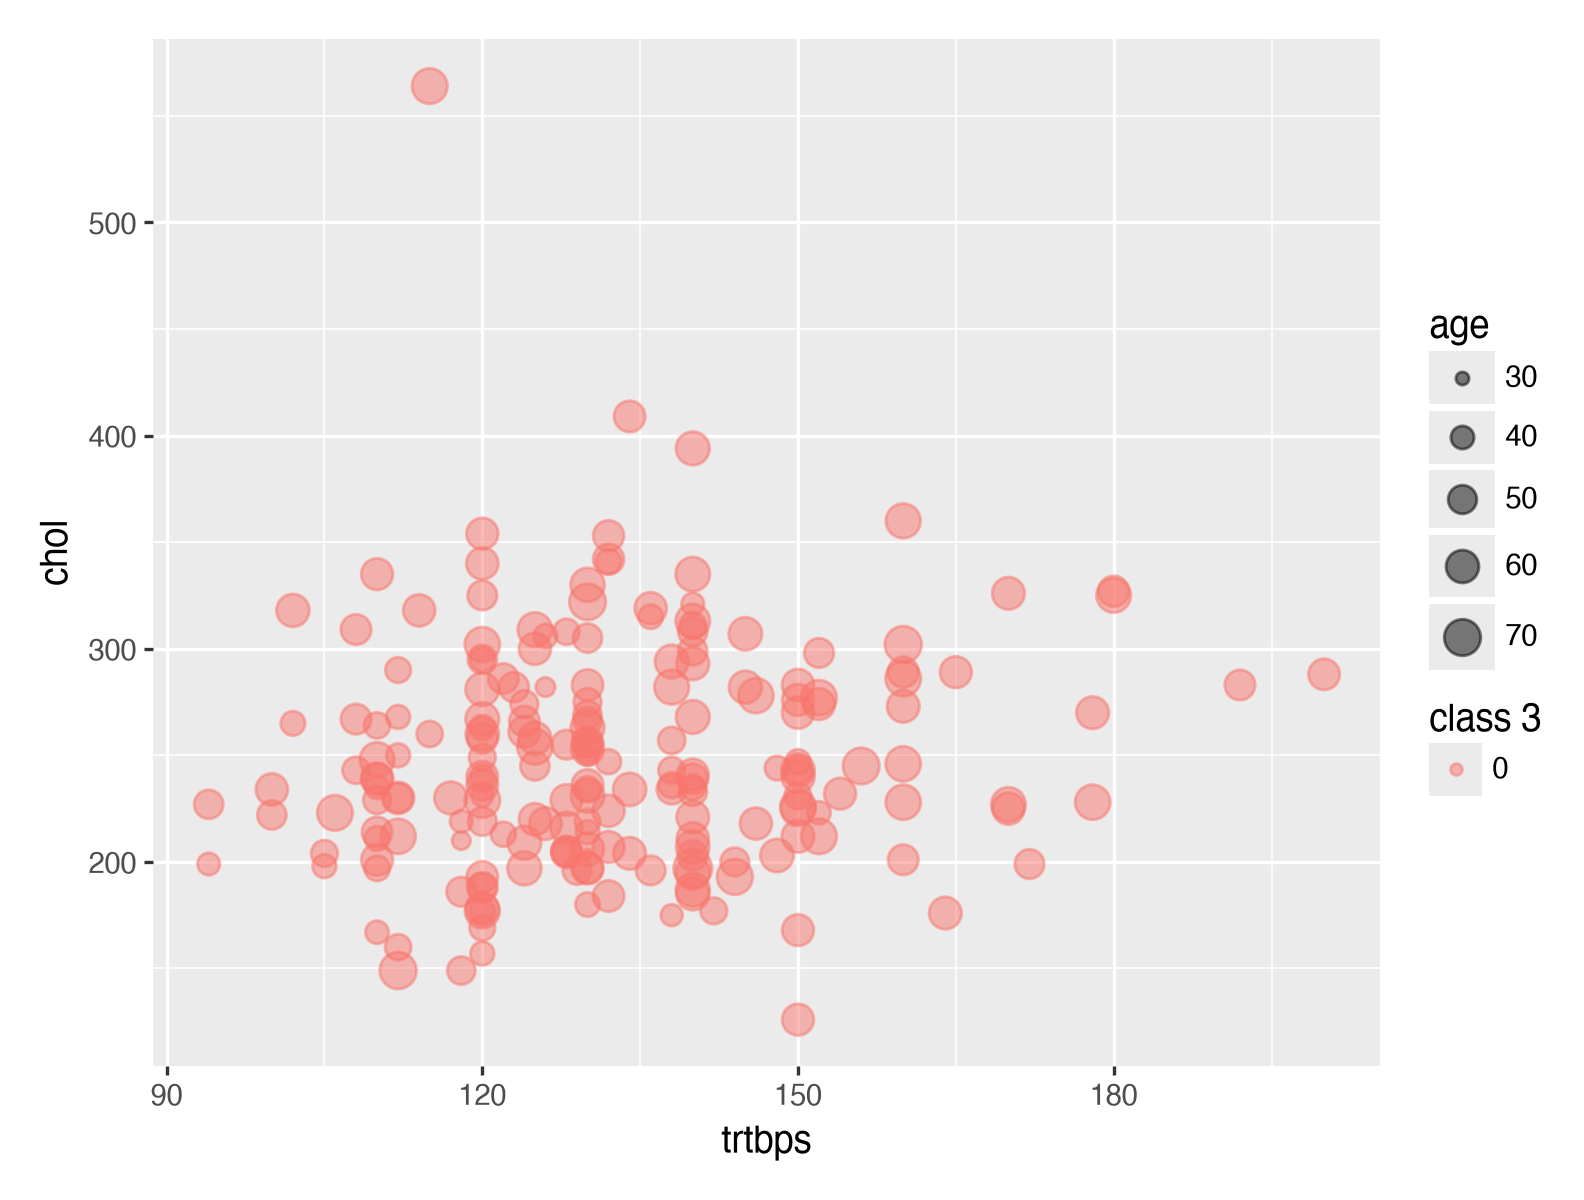

In [6]:
y_train_3 = ha.loc[X_train.index, "cp_is_3"]
y_test_3 = ha.loc[X_test.index, "cp_is_3"]

logit_3 = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression())
])

logit_3.fit(X_train, y_train_3)

display(pd.DataFrame(logit_3.predict_proba(X_train), columns=["not class 3", "class 3"], index=X_train.index))

pred_3 = logit_3.predict(X_test)
print("test precision:", precision_score(y_test_3, pred_3, zero_division=0))
print("test recall:", recall_score(y_test_3, pred_3, zero_division=0))
print("test f1:", f1_score(y_test_3, pred_3, zero_division=0))

plot_3 = X_train.assign(predicted=logit_3.predict(X_train).astype(str))
(ggplot(plot_3, aes(x="trtbps", y="chol", size="age", color="predicted"))
+ geom_point(alpha=0.5)
+ labs(color="class 3"))

## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

class 0


,not class 0,class 0
133,0.466644,0.533356
157,0.396961,0.603039
130,0.668398,0.331602
78,0.533468,0.466532
247,0.519716,0.480284
...,...,...
56,0.523489,0.476511
21,0.515588,0.484412
40,0.622456,0.377544
94,0.585546,0.414454


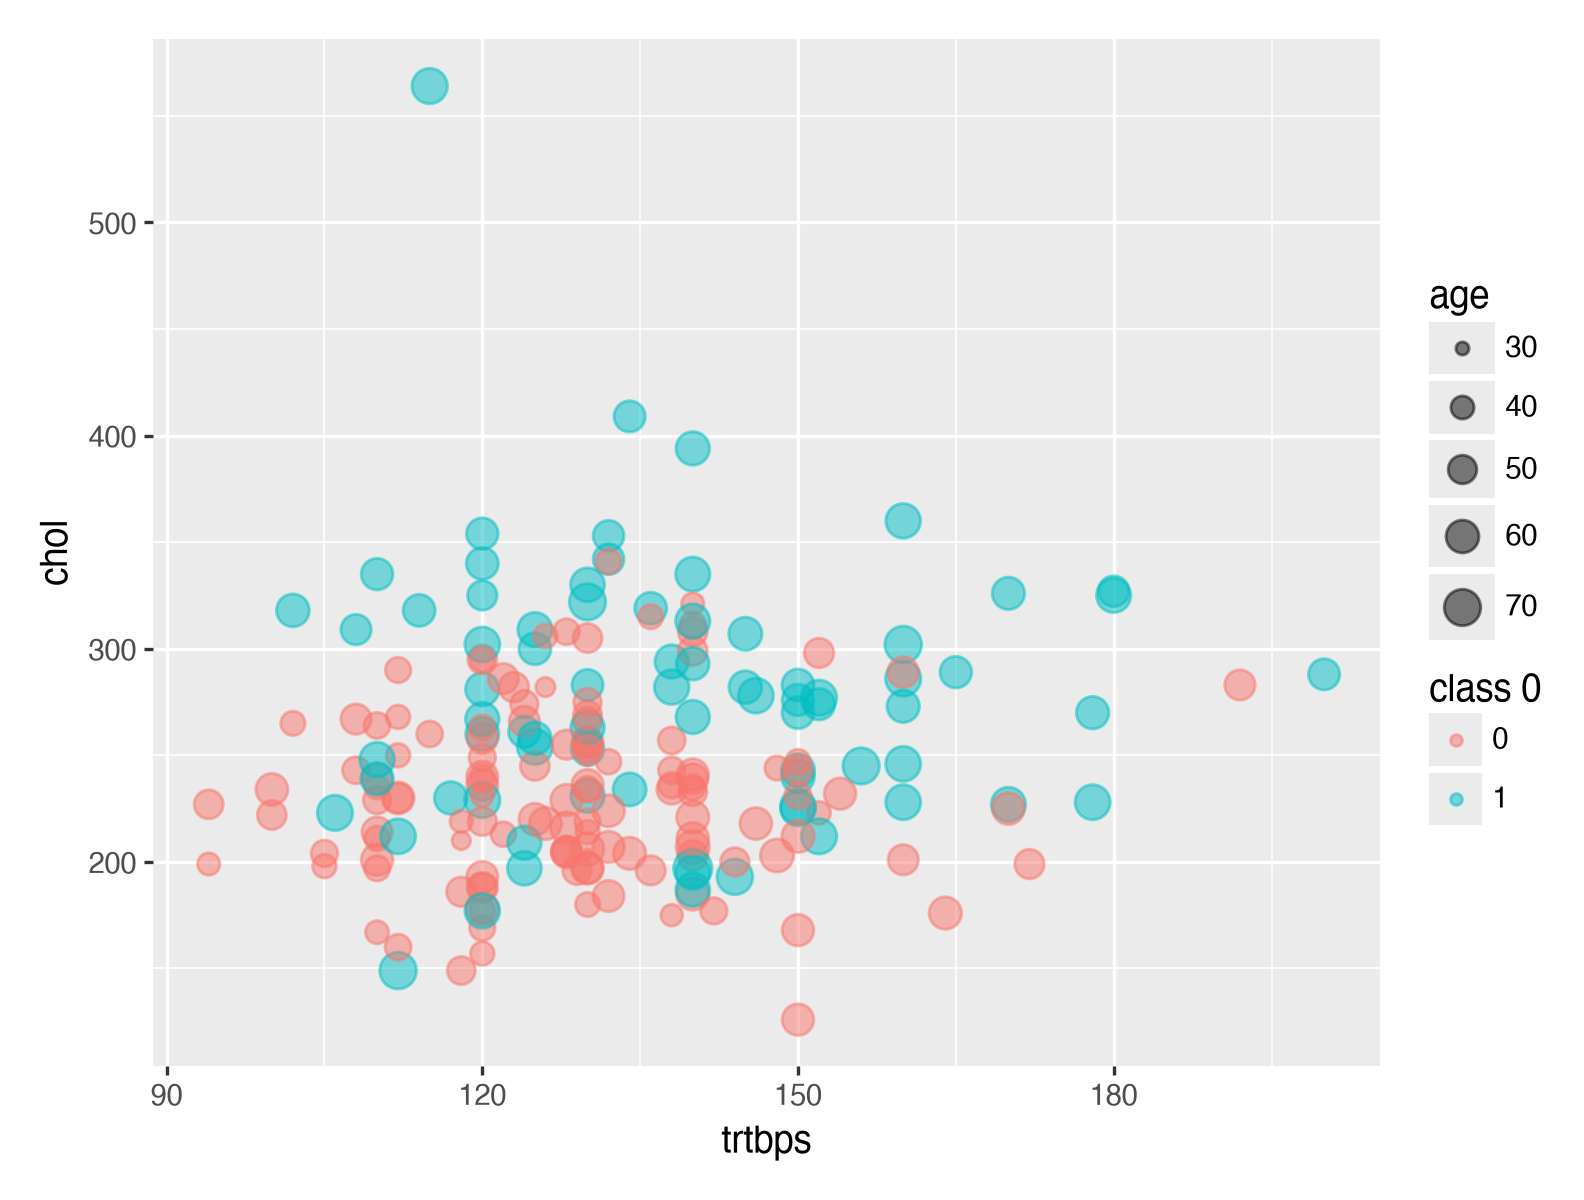

class 1


,not class 1,class 1
133,0.915881,0.084119
157,0.887807,0.112193
130,0.776115,0.223885
78,0.866183,0.133817
247,0.879448,0.120552
...,...,...
56,0.876211,0.123789
21,0.887232,0.112768
40,0.790557,0.209443
94,0.888761,0.111239


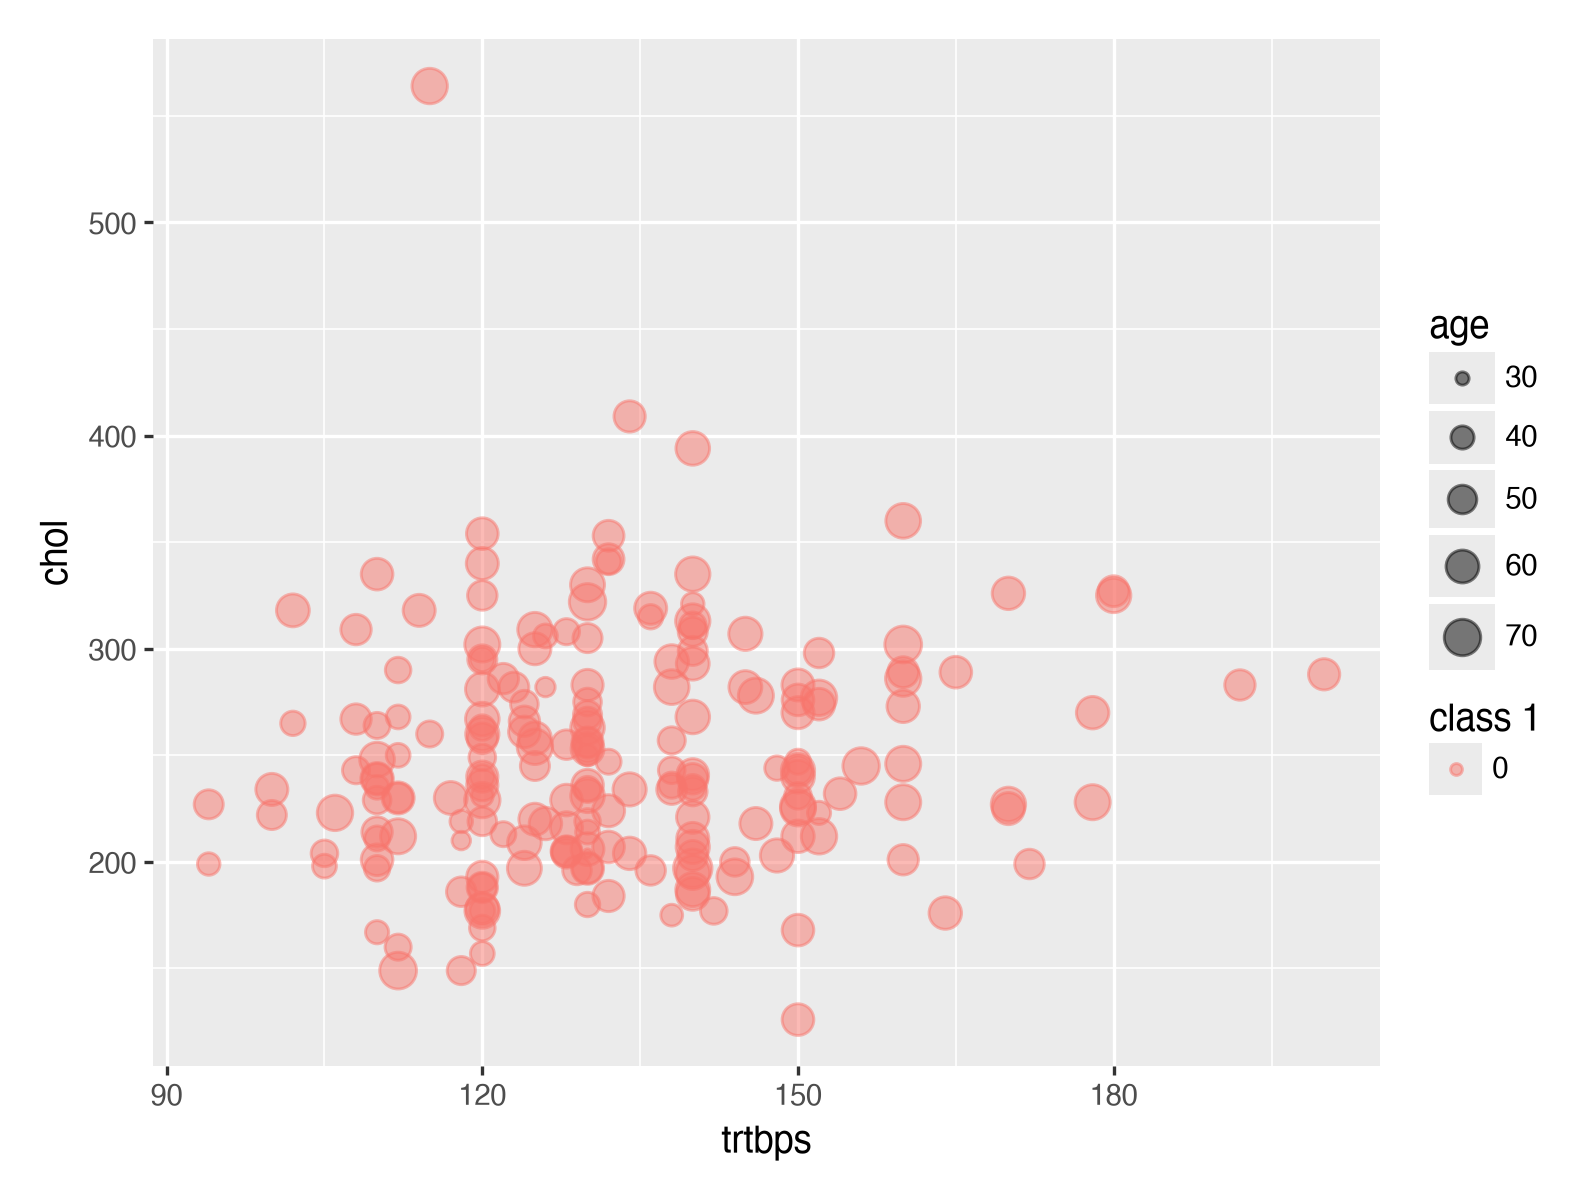

class 2


,not class 2,class 2
133,0.764186,0.235814
157,0.783537,0.216463
130,0.632319,0.367681
78,0.690730,0.309270
247,0.717532,0.282468
...,...,...
56,0.705951,0.294049
21,0.721564,0.278436
40,0.685384,0.314616
94,0.666556,0.333444


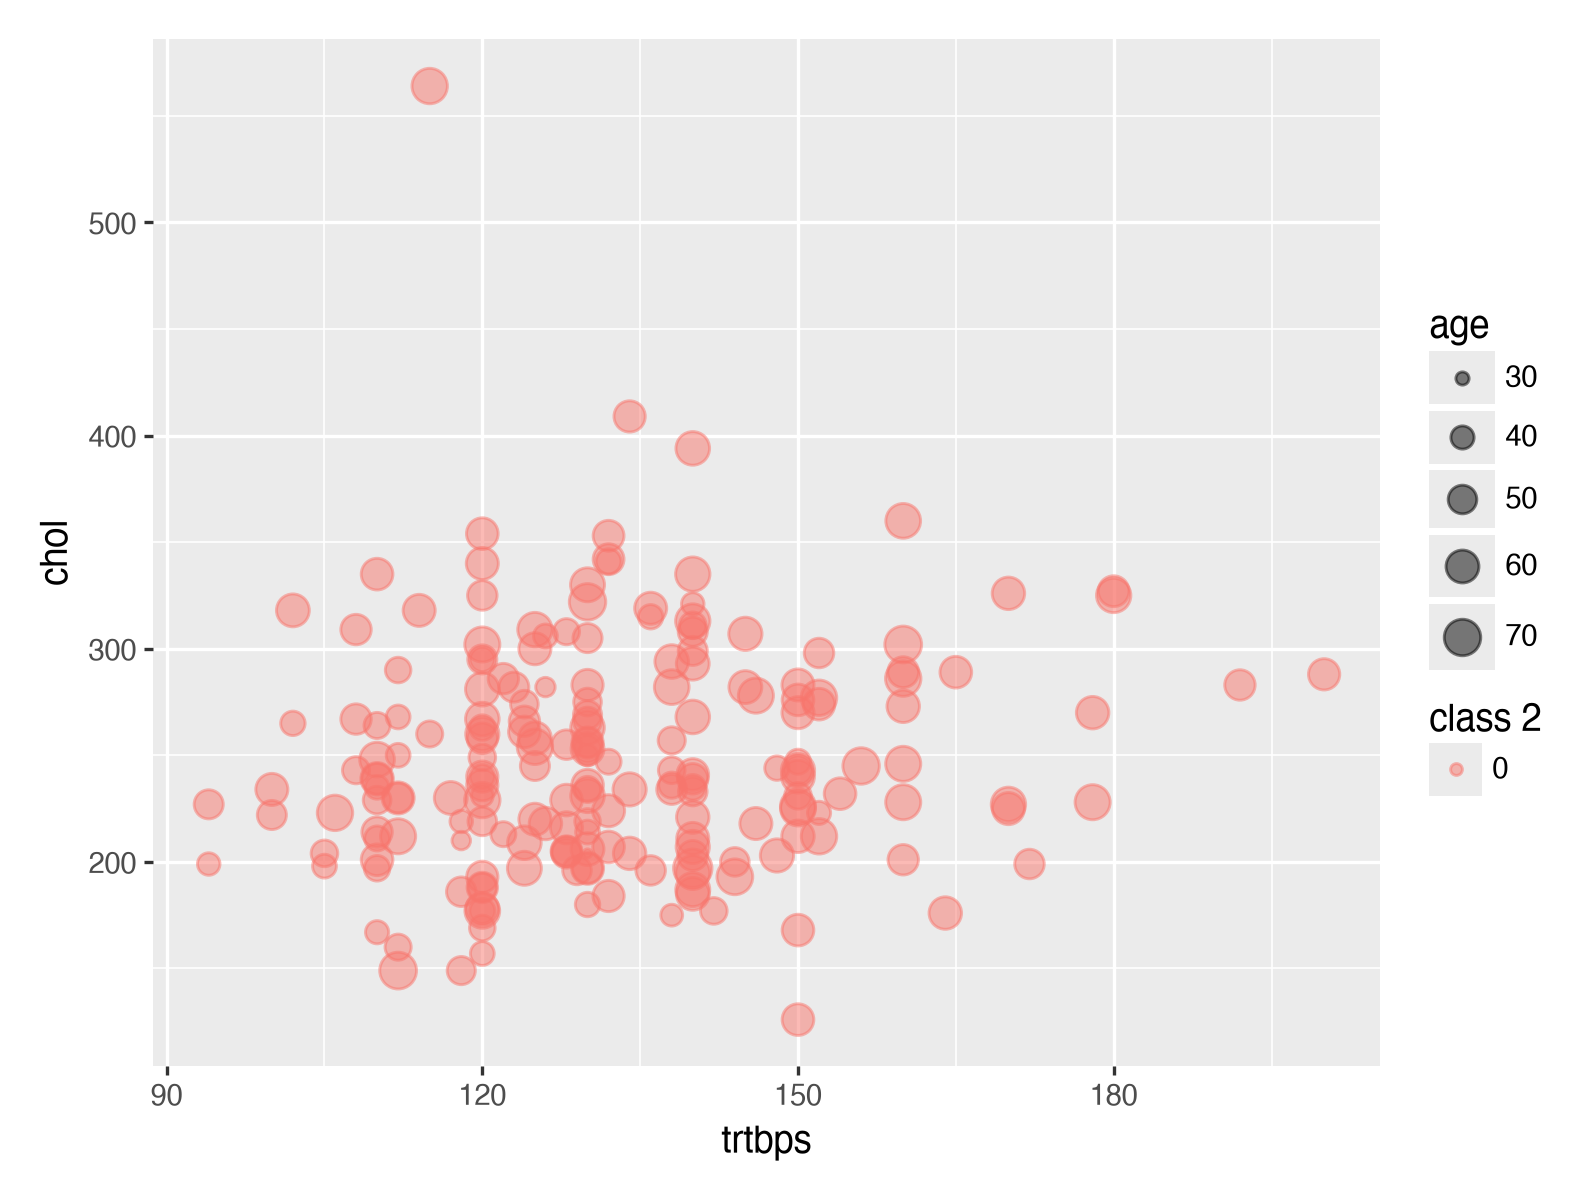

,class,precision,recall,f1
0,0,0.548387,0.53125,0.539683
1,1,0.000000,0.00000,0.000000
2,2,0.000000,0.00000,0.000000
3,3,0.000000,0.00000,0.000000


best class by test f1: 0


In [7]:
ovr_results = []

for category in [0, 1, 2]:
    y_train_class = ha.loc[X_train.index, "cp_is_" + str(category)]
    y_test_class = ha.loc[X_test.index, "cp_is_" + str(category)]

    logit = Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression())
    ])

    logit.fit(X_train, y_train_class)

    print("class", category)
    display(pd.DataFrame(logit.predict_proba(X_train), columns=["not class " + str(category), "class " + str(category)], index=X_train.index))

    pred = logit.predict(X_test)
    ovr_results.append({
        "class": category,
        "precision": precision_score(y_test_class, pred, zero_division=0),
        "recall": recall_score(y_test_class, pred, zero_division=0),
        "f1": f1_score(y_test_class, pred, zero_division=0)
    })

    plot_data = X_train.assign(predicted=logit.predict(X_train).astype(str))
    plot = ggplot(plot_data, aes(x="trtbps", y="chol", size="age", color="predicted"))
    plot = plot + geom_point(alpha=0.5) + labs(color="class " + str(category))
    plot.show()

ovr_results.append({
    "class": 3,
    "precision": precision_score(y_test_3, pred_3, zero_division=0),
    "recall": recall_score(y_test_3, pred_3, zero_division=0),
    "f1": f1_score(y_test_3, pred_3, zero_division=0)
})

ovr_results = pd.DataFrame(ovr_results)
display(ovr_results)
print("best class by test f1:", ovr_results.loc[ovr_results["f1"].idxmax(), "class"])

## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [8]:
ha_01 = ha[ha["cp"].isin(["0", "1"])]

X_01 = ha_01[["trtbps", "chol", "age"]]
y_01 = ha_01["cp"]

X_train_01, X_test_01, y_train_01, y_test_01 = train_test_split(X_01, y_01, test_size=0.25, random_state=1, stratify=y_01)

logit_01 = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression())
])

logit_01.fit(X_train_01, y_train_01)

prob_01 = logit_01.predict_proba(X_test_01)[:, 1]
auc_01 = roc_auc_score(y_test_01, prob_01)
print("test roc-auc for 0 vs 1:", auc_01)

test roc-auc for 0 vs 1: 0.6448863636363636


## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

In [9]:
ovo_results = [{"pair": "0 vs 1", "roc_auc": auc_01}]

for category in ["2", "3"]:
    ha_pair = ha[ha["cp"].isin(["0", category])]

    X_pair = ha_pair[["trtbps", "chol", "age"]]
    y_pair = ha_pair["cp"]

    X_train_pair, X_test_pair, y_train_pair, y_test_pair = train_test_split(X_pair, y_pair, test_size=0.25, random_state=1, stratify=y_pair)

    logit_pair = Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression())
    ])

    logit_pair.fit(X_train_pair, y_train_pair)

    prob_pair = logit_pair.predict_proba(X_test_pair)[:, 1]
    ovo_results.append({
        "pair": "0 vs " + category,
        "roc_auc": roc_auc_score(y_test_pair, prob_pair)
    })

ovo_results = pd.DataFrame(ovo_results)
display(ovo_results)
print("best pair by test roc-auc:", ovo_results.loc[ovo_results["roc_auc"].idxmax(), "pair"])

,pair,roc_auc
0,0 vs 1,0.644886
1,0 vs 2,0.430060
2,0 vs 3,0.668750


best pair by test roc-auc: 0 vs 3


The best OvR category is the one with the highest test F1 score in the table. The best OvO pair is the one with the highest test ROC-AUC. A ROC-AUC near 0.5 means the model does little better than random ranking; higher values mean better separation.